# Лабораторная работа №3. Кластеризация

## Задание 1. Кластеризация изотопного состава плутония методом k-means
Разбить множество объектов из набора данных pluton.csv на 3 кластера с помощью k-means и сравнить качество разбиения в зависимости от максимального числа итераций алгоритма и использования стандартизации.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score, calinski_harabasz_score, davies_bouldin_score

pluton = pd.read_csv('pluton.csv')
print(pluton.shape)
pluton.describe().round(3)

(45, 4)


,Pu238,Pu239,Pu240,Pu241
count,45.000,45.000,45.000,45.000
mean,0.722,69.935,21.533,5.330
std,0.574,7.133,2.412,3.016
min,0.102,58.688,17.872,1.674
25%,0.162,61.585,19.108,2.365
50%,0.397,72.907,21.429,3.836
75%,1.309,75.751,23.239,8.300
max,1.638,79.840,25.719,9.972


In [2]:
# Эталонные разбиения: k-means++ с 10 стартами, без стандартизации и со стандартизацией
X_raw = pluton.values
X_std = StandardScaler().fit_transform(X_raw)

ref_raw = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_raw)
ref_std = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_std)
print('Итераций до сходимости: без стандартизации', ref_raw.n_iter_, ', со стандартизацией', ref_std.n_iter_)
print('ARI между двумя эталонными разбиениями:', round(adjusted_rand_score(ref_raw.labels_, ref_std.labels_), 3))
print('Silhouette: без стандартизации', round(silhouette_score(X_raw, ref_raw.labels_), 3),
      ', со стандартизацией', round(silhouette_score(X_std, ref_std.labels_), 3))

Итераций до сходимости: без стандартизации 2 , со стандартизацией 6
ARI между двумя эталонными разбиениями: 1.0
Silhouette: без стандартизации 0.668 , со стандартизацией 0.699


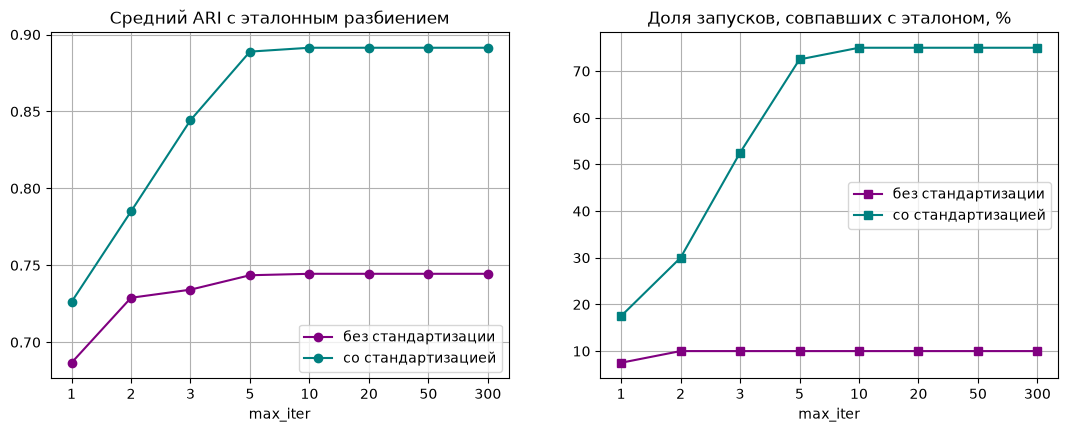

средний ARI                    доля совпадений, %  \
данные   без стандартизации со стандартизацией без стандартизации   
max_iter                                                            
1                     0.687              0.726                7.5   
2                     0.729              0.785               10.0   
3                     0.734              0.844               10.0   
5                     0.744              0.889               10.0   
10                    0.744              0.891               10.0   
20                    0.744              0.891               10.0   
50                    0.744              0.891               10.0   
300                   0.744              0.891               10.0   

                             
данные   со стандартизацией  
max_iter                     
1                      17.5  
2                      30.0  
3                      52.5  
5                      72.5  
10                     75.0  
20                     75.0  
50                     75.0  
300                    75.0

In [3]:
# Влияние max_iter: 40 запусков со случайными начальными центрами (init='random', n_init=1)
iters = [1, 2, 3, 5, 10, 20, 50, 300]
rows = []
for X, ref, name in [(X_raw, ref_raw.labels_, 'без стандартизации'), (X_std, ref_std.labels_, 'со стандартизацией')]:
    for it in iters:
        aris = [adjusted_rand_score(ref, KMeans(n_clusters=3, init='random', n_init=1, max_iter=it,
                                                random_state=s).fit_predict(X)) for s in range(40)]
        rows.append({'данные': name, 'max_iter': it, 'средний ARI': np.mean(aris),
                     'доля совпадений, %': 100 * np.mean(np.array(aris) > 0.99)})
iter_tab = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, color in [('без стандартизации', 'purple'), ('со стандартизацией', 'teal')]:
    part = iter_tab[iter_tab['данные'] == name]
    ax[0].plot(range(len(iters)), part['средний ARI'], marker='o', color=color, label=name)
    ax[1].plot(range(len(iters)), part['доля совпадений, %'], marker='s', color=color, label=name)
for a, title in zip(ax, ['Средний ARI с эталонным разбиением', 'Доля запусков, совпавших с эталоном, %']):
    a.set_xticks(range(len(iters)))
    a.set_xticklabels(iters)
    a.set_xlabel('max_iter')
    a.set_title(title)
    a.legend()
    a.grid(True)
plt.show()

iter_tab.pivot(index='max_iter', columns='данные', values=['средний ARI', 'доля совпадений, %']).round(3)

In [4]:
# Состав кластеров (эталонное разбиение со стандартизацией), кластеры упорядочены по убыванию Pu239
order = pluton.groupby(ref_std.labels_)['Pu239'].mean().sort_values(ascending=False).index
cl = pd.Series(ref_std.labels_).map({old: new + 1 for new, old in enumerate(order)}).values
comp = pluton.groupby(cl).mean().round(2)
comp.insert(0, 'n', pd.Series(cl).value_counts().sort_index().values)
comp.index.name = 'кластер'
comp

,n,Pu238,Pu239,Pu240,Pu241
кластер,,,,,
1,24,0.21,75.69,20.50,2.66
2,6,1.11,70.18,18.52,7.67
3,15,1.38,60.63,24.39,8.67


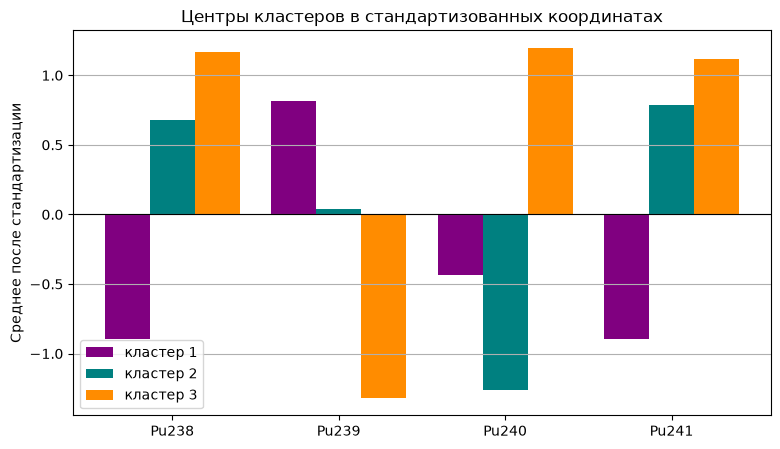

In [5]:
# Центры кластеров в стандартизованных координатах
centers = pd.DataFrame(X_std, columns=pluton.columns).groupby(cl).mean()
x = np.arange(len(pluton.columns))
plt.figure(figsize=(9, 5))
for j, (k, color) in enumerate(zip(centers.index, ['purple', 'teal', 'darkorange'])):
    plt.bar(x + (j - 1) * 0.27, centers.loc[k], width=0.27, color=color, label=f'кластер {k}')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(x, pluton.columns)
plt.ylabel('Среднее после стандартизации')
plt.title('Центры кластеров в стандартизованных координатах')
plt.legend()
plt.grid(True, axis='y')
plt.show()

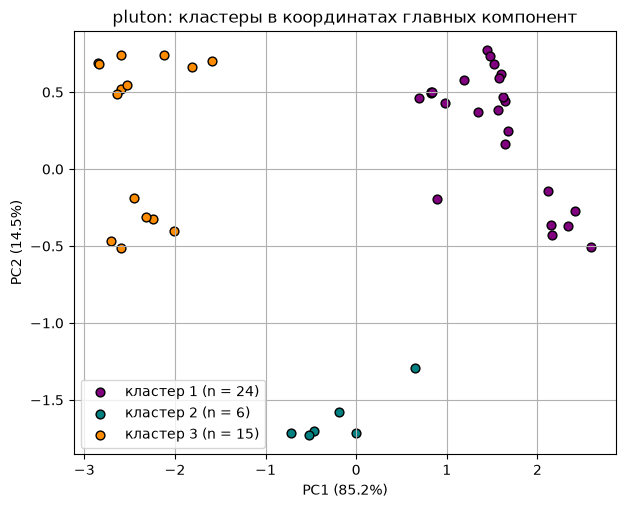

Доля дисперсии двух компонент: 0.997


In [6]:
# Образцы в координатах первых двух главных компонент
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(X_std)
P = pca.transform(X_std)
plt.figure(figsize=(7, 5.5))
for k, color in zip([1, 2, 3], ['purple', 'teal', 'darkorange']):
    plt.scatter(P[cl == k, 0], P[cl == k, 1], color=color, edgecolor='k', s=40, label=f'кластер {k} (n = {(cl == k).sum()})')
plt.xlabel(f'PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}%)')
plt.ylabel(f'PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}%)')
plt.title('pluton: кластеры в координатах главных компонент')
plt.legend()
plt.grid(True)
plt.show()
print('Доля дисперсии двух компонент:', round(pca.explained_variance_ratio_.sum(), 3))

### Выводы по заданию 1
В данных pluton есть три устойчивые группы образцов, и k-means находит их как на исходных, так и на стандартизованных признаках: эталонные разбиения совпадают полностью. Группы различаются изотопным составом - от образцов с высокой долей Pu239 до образцов с повышенными долями более тяжёлых изотопов.

Параметр max_iter важен только до тех пор, пока алгоритм не успел сойтись: на этих данных после 10 итераций результат не меняется. Стандартизация не меняет итоговые группы, но сильно повышает надёжность случайного старта: доля запусков, пришедших к эталонному разбиению, растёт с 10 до 75 %, потому что Pu239 с его большим разбросом перестаёт подавлять остальные признаки.

## Задание 2. Сравнение k-means, DBSCAN и иерархической кластеризации
Разбить на кластеры множество объектов из наборов данных clustering_1.csv, clustering_2.csv и clustering_3.csv с помощью k-means, DBSCAN и иерархической кластеризации, определить оптимальное количество кластеров (где это применимо), оценить качество разбиения с помощью метрик, визуализировать разбиения и сравнить визуальную оценку с оценкой по метрикам.

clustering_1: 800 точек
clustering_2: 1200 точек
clustering_3: 1600 точек
Выбранное k: {(1, 'Ward'): 2, (1, 'k-means'): 2, (2, 'Ward'): 3, (2, 'k-means'): 3, (3, 'Ward'): 6, (3, 'k-means'): 6}


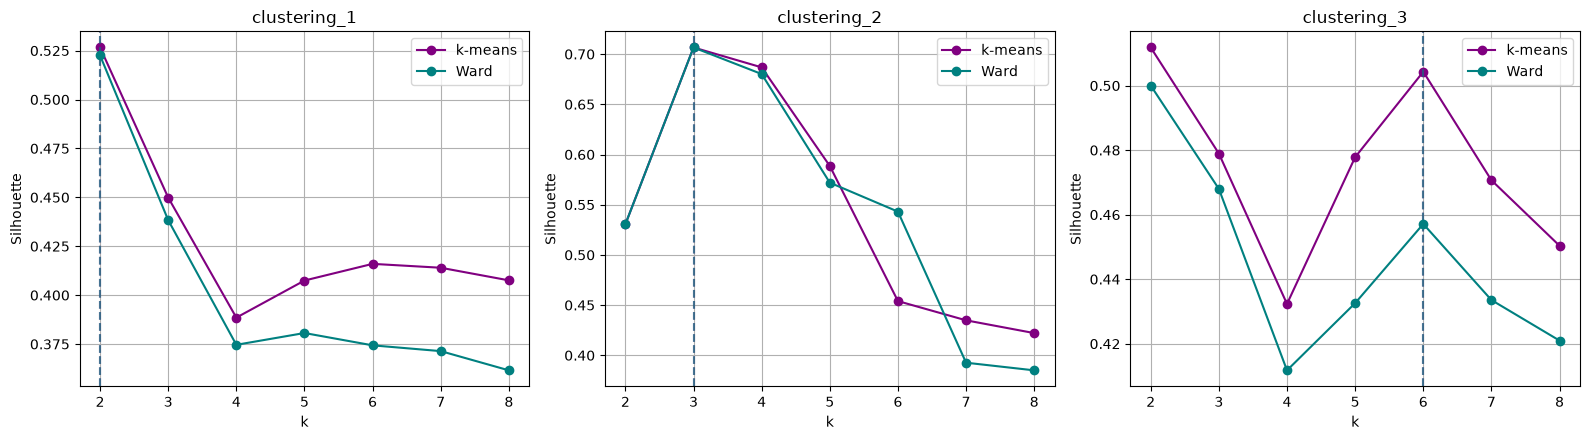

In [7]:
# Наборы clustering_1–3: число кластеров для k-means и метода Уорда (k = 2…8)
sets = {n: pd.read_csv(f'clustering_{n}.csv', sep='\t', header=None, names=['X1', 'X2']).values for n in [1, 2, 3]}
for n, X in sets.items():
    print(f'clustering_{n}: {len(X)} точек')

def fit_labels(method, X, k):
    if method == 'k-means':
        return KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    return AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)

ks = range(2, 9)
k_rows = []
for n, X in sets.items():
    for method in ['k-means', 'Ward']:
        for k in ks:
            lbl = fit_labels(method, X, k)
            k_rows.append({'набор': n, 'метод': method, 'k': k,
                           'silhouette': silhouette_score(X, lbl),
                           'CH': calinski_harabasz_score(X, lbl),
                           'DB': davies_bouldin_score(X, lbl)})
k_tab = pd.DataFrame(k_rows)

# Правило выбора: минимум индекса Дэвиса–Болдина при silhouette не ниже максимума минус 0.05
best_k = {}
for (n, method), part in k_tab.groupby(['набор', 'метод']):
    ok = part[part['silhouette'] >= part['silhouette'].max() - 0.05]
    best_k[(n, method)] = int(ok.loc[ok['DB'].idxmin(), 'k'])
print('Выбранное k:', best_k)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, n in zip(ax, sets):
    for method, color in [('k-means', 'purple'), ('Ward', 'teal')]:
        part = k_tab[(k_tab['набор'] == n) & (k_tab['метод'] == method)]
        a.plot(part['k'], part['silhouette'], marker='o', color=color, label=method)
        a.axvline(best_k[(n, method)], linestyle='--', color=color, alpha=0.6)
    a.set_title(f'clustering_{n}')
    a.set_xlabel('k')
    a.set_ylabel('Silhouette')
    a.legend()
    a.grid(True)
plt.tight_layout()
plt.show()

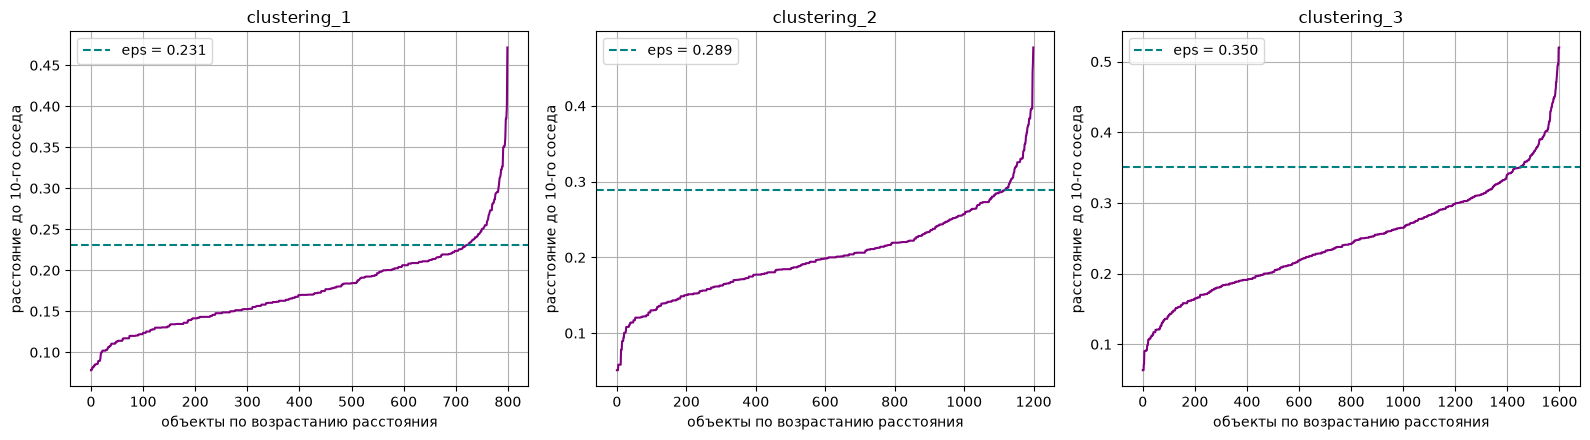

In [8]:
# DBSCAN: выбор eps по графику расстояния до 10-го соседа (min_samples = 10)
from sklearn.neighbors import NearestNeighbors
min_samples = 10
eps_val = {}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (n, X) in zip(ax, sets.items()):
    d = np.sort(NearestNeighbors(n_neighbors=min_samples + 1).fit(X).kneighbors(X)[0][:, -1])
    i = np.arange(len(d))
    # «локоть»: точка, наиболее удалённая от прямой, соединяющей концы графика
    dist = np.abs((d[-1] - d[0]) * i - (len(d) - 1) * (d - d[0])) / np.hypot(d[-1] - d[0], len(d) - 1)
    eps_val[n] = d[np.argmax(dist)]
    a.plot(i, d, color='purple')
    a.axhline(eps_val[n], linestyle='--', color='teal', label=f'eps = {eps_val[n]:.3f}')
    a.set_title(f'clustering_{n}')
    a.set_xlabel('объекты по возрастанию расстояния')
    a.set_ylabel('расстояние до 10-го соседа')
    a.legend()
    a.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# Метрики выбранных разбиений
labels = {}
m_rows = []
for n, X in sets.items():
    for method in ['k-means', 'DBSCAN', 'Ward']:
        if method == 'DBSCAN':
            lbl = DBSCAN(eps=eps_val[n], min_samples=min_samples).fit_predict(X)
        else:
            lbl = fit_labels(method, X, best_k[(n, method)])
        labels[(n, method)] = lbl
        mask = lbl != -1                     # точки шума DBSCAN в метриках не учитываются
        n_cl = len(set(lbl[mask]))
        row = {'набор': n, 'метод': method, 'кластеров': n_cl, 'шум, %': round(100 * (~mask).mean(), 1)}
        if n_cl > 1:
            row.update({'silhouette': round(silhouette_score(X[mask], lbl[mask]), 3),
                        'CH': round(calinski_harabasz_score(X[mask], lbl[mask])),
                        'DB': round(davies_bouldin_score(X[mask], lbl[mask]), 3)})
        m_rows.append(row)
pd.DataFrame(m_rows)

,набор,метод,кластеров,"шум, %",silhouette,CH,DB
0,1,k-means,2,0.0,0.527,1361.0,0.722
1,1,DBSCAN,1,1.6,NaN,NaN,NaN
2,1,Ward,2,0.0,0.523,1342.0,0.728
3,2,k-means,3,0.0,0.707,4085.0,0.445
4,2,DBSCAN,3,0.2,0.707,4085.0,0.445
5,2,Ward,3,0.0,0.707,4085.0,0.445
6,3,k-means,6,0.0,0.504,3109.0,0.645
7,3,DBSCAN,4,0.4,0.193,980.0,0.975
8,3,Ward,6,0.0,0.457,2649.0,0.708


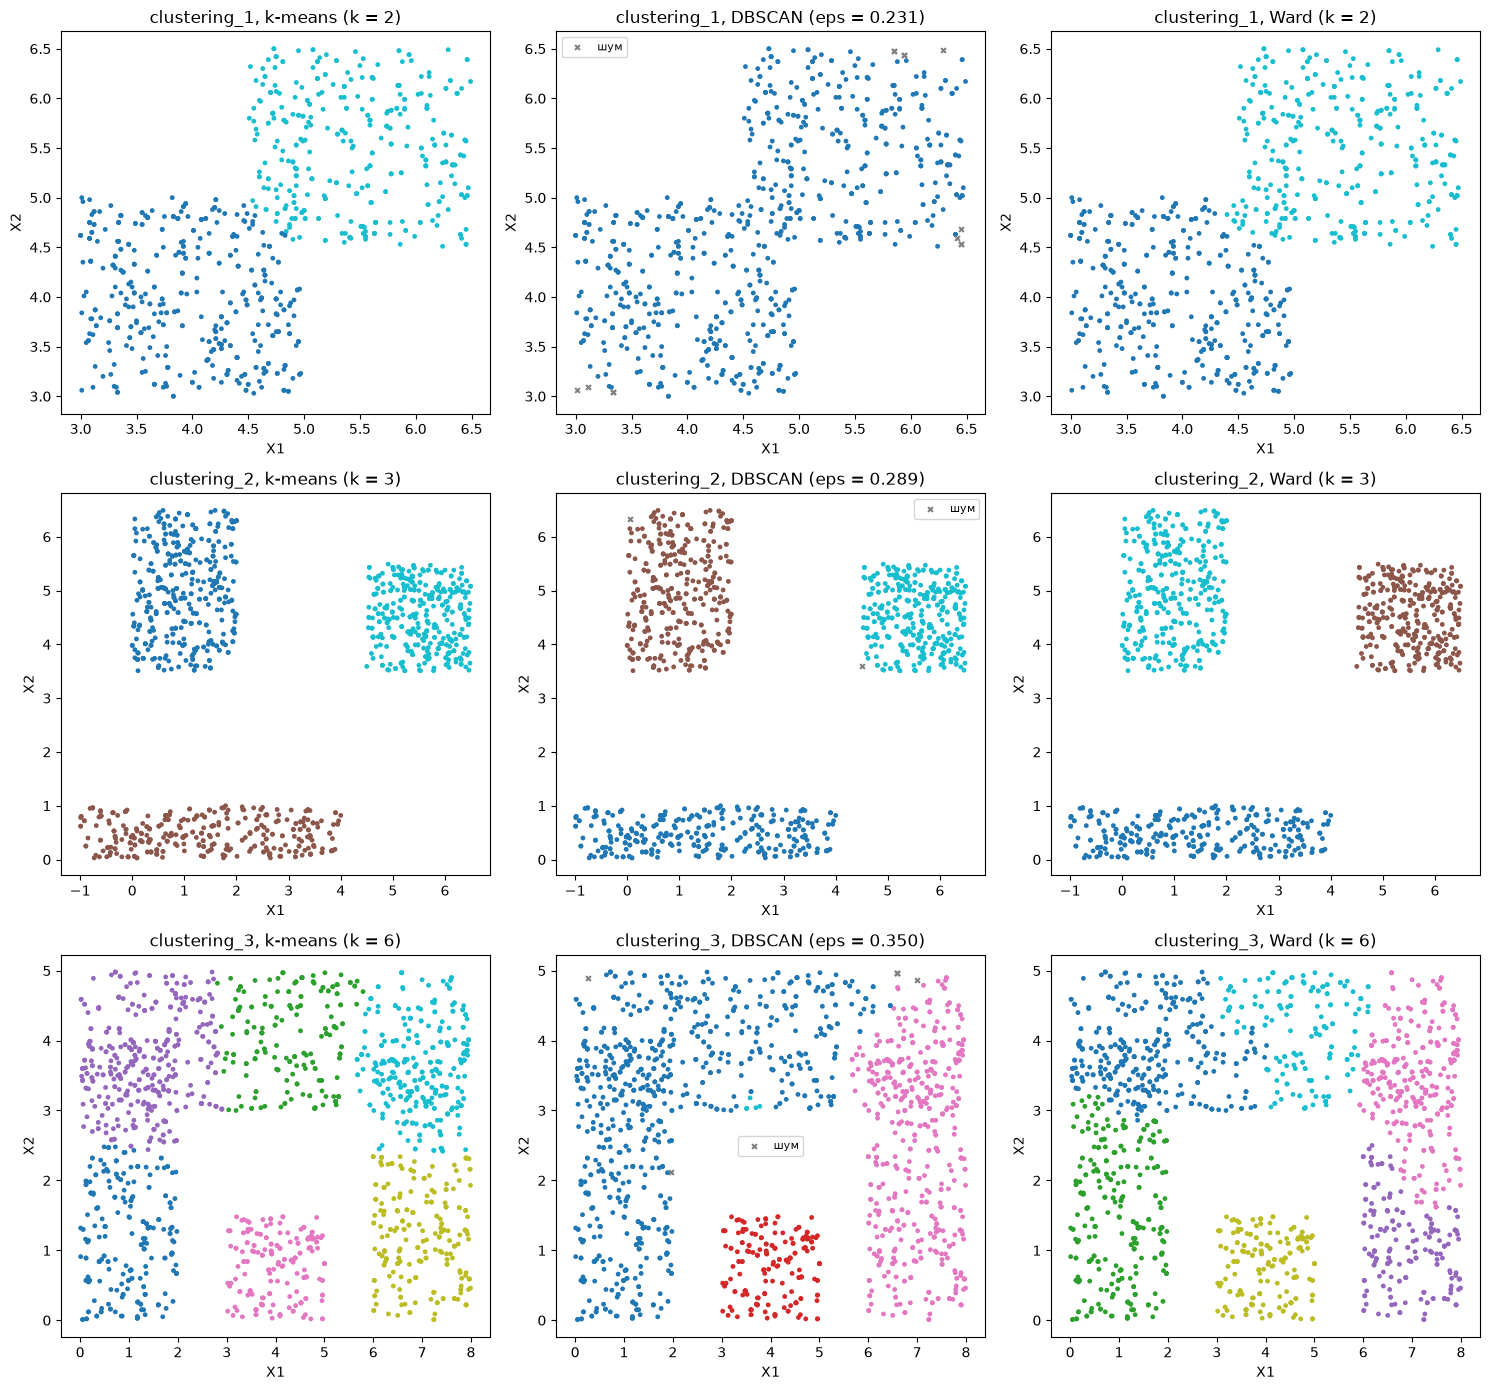

In [10]:
# Разбиения трёх наборов: строки - наборы, столбцы - методы
fig, ax = plt.subplots(3, 3, figsize=(15, 14))
for r, (n, X) in enumerate(sets.items()):
    for c, method in enumerate(['k-means', 'DBSCAN', 'Ward']):
        lbl = labels[(n, method)]
        a = ax[r, c]
        noise = lbl == -1
        a.scatter(X[~noise, 0], X[~noise, 1], c=lbl[~noise], cmap='tab10', s=6)
        if noise.any():
            a.scatter(X[noise, 0], X[noise, 1], color='gray', marker='x', s=12, label='шум')
            a.legend(fontsize=8)
        k_txt = f'eps = {eps_val[n]:.3f}' if method == 'DBSCAN' else f'k = {best_k[(n, method)]}'
        a.set_title(f'clustering_{n}, {method} ({k_txt})')
        a.set_xlabel('X1')
        a.set_ylabel('X2')
plt.tight_layout()
plt.show()

### Выводы по заданию 2
На первых двух наборах визуальная оценка совпадает с оценкой по метрикам. На clustering_1 лучше всего работают k-means и метод Уорда при k = 2, а DBSCAN не может разделить облака, между которыми нет разрыва плотности. На clustering_2 все три метода дают одинаковое и правильное разбиение на три группы.

На clustering_3 оценки расходятся: по метрикам лучший k-means, а визуально лучший DBSCAN, так как только он выделяет кластеры произвольной формы и не разрезает плотные полосы. Поэтому лучшего метода «вообще» нет: k-means и метод Уорда подходят для компактных хорошо разделённых групп, DBSCAN - для кластеров сложной формы и когда число кластеров заранее неизвестно. Внутренние метрики качества нужно обязательно проверять визуально, если кластеры могут быть невыпуклыми.

## Задание 3. Сжатие цветовой палитры изображения
Осуществить сжатие цветовой палитры изображения: выделить n кластеров из цветов всех пикселей, заменить цвет каждого пикселя центром его кластера и сравнить исходное и сжатое изображения.

Размер: 427 × 640 , различных цветов: 96615


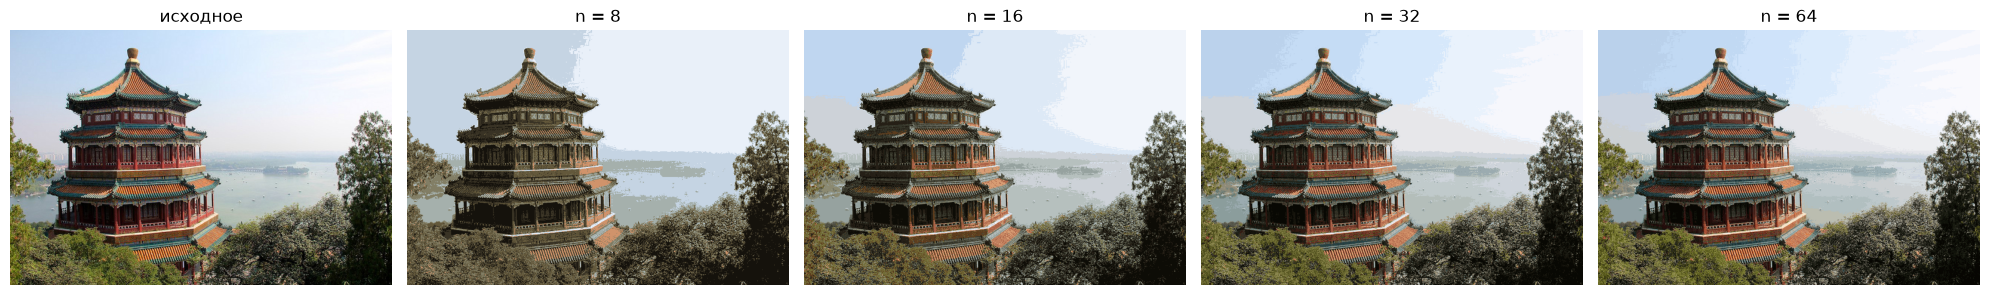

In [11]:
# Сжатие цветовой палитры: изображение china.jpg из примеров scikit-learn
from sklearn.datasets import load_sample_image
img = load_sample_image('china.jpg')
h, w, _ = img.shape
pixels = img.reshape(-1, 3).astype(float)
print('Размер:', h, '×', w, ', различных цветов:', len(np.unique(img.reshape(-1, 3), axis=0)))

rng = np.random.default_rng(42)
sample = pixels[rng.choice(len(pixels), 20000, replace=False)]   # подвыборка пикселей для обучения
results = {}
for n_colors in [8, 16, 32, 64]:
    km = KMeans(n_clusters=n_colors, n_init=4, random_state=42).fit(sample)
    results[n_colors] = km.cluster_centers_[km.predict(pixels)].reshape(h, w, 3).astype(np.uint8)

fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
ax[0].imshow(img)
ax[0].set_title('исходное')
for a, (n_colors, im) in zip(ax[1:], results.items()):
    a.imshow(im)
    a.set_title(f'n = {n_colors}')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

### Выводы по заданию 3
k-means в пространстве RGB позволяет сократить палитру до любого заданного числа цветов, сохраняя общий вид изображения. Для этого изображения 8 цветов уже заметно искажают плавные переходы, 16–32 цвета - разумный компромисс между размером палитры и качеством, а 64 цвета визуально почти неотличимы от исходных 96 615.

## Задание 4. Дендрограмма голосования за республиканцев по штатам США
Построить дендрограмму для набора данных votes.csv (доля голосов, поданных за республиканцев на президентских выборах с 1856 по 1976 год) и проинтерпретировать полученный результат.

(50, 31)  пропусков: 217
k = 2  silhouette = 0.532
k = 3  silhouette = 0.285
k = 4  silhouette = 0.253
k = 5  silhouette = 0.255
k = 6  silhouette = 0.263


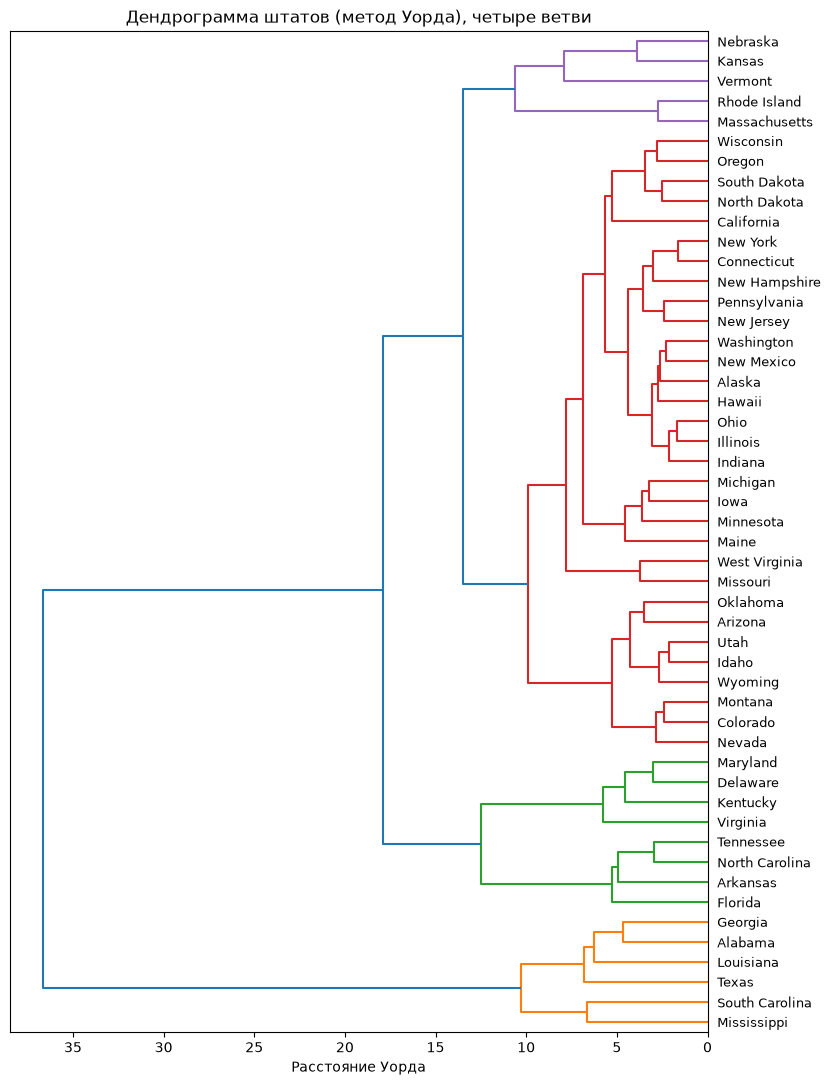

In [12]:
# Дендрограмма голосования по штатам (votes.csv)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
votes = pd.read_csv('votes.csv')
states = ['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware',
          'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky',
          'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi',
          'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico',
          'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania',
          'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont',
          'Virginia', 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming']
votes.index = states
print(votes.shape, ' пропусков:', votes.isna().sum().sum())

V = StandardScaler().fit_transform(votes.fillna(votes.median()))   # пропуски - медианой года
Z = linkage(V, method='ward')
for k in range(2, 7):
    print('k =', k, ' silhouette =', round(silhouette_score(V, fcluster(Z, k, 'maxclust')), 3))

plt.figure(figsize=(9, 13))
dendrogram(Z, labels=states, orientation='left', color_threshold=Z[-4, 2] + 1e-9, leaf_font_size=9)
plt.xlabel('Расстояние Уорда')
plt.title('Дендрограмма штатов (метод Уорда), четыре ветви')
plt.show()

In [13]:
# Четыре ветви дендрограммы
branch = fcluster(Z, 4, 'maxclust')
early = [c for c in votes.columns if int(c[1:]) <= 1892]
late = [c for c in votes.columns if int(c[1:]) >= 1948]
br_rows = []
for b in sorted(set(branch)):
    part = votes[branch == b]
    br_rows.append({'ветвь': b, 'n': len(part),
                    'среднее, %': round(np.nanmean(part.values), 1),
                    '1856–1892, %': round(np.nanmean(part[early].values), 1),
                    '1948–1976, %': round(np.nanmean(part[late].values), 1),
                    'штаты': ', '.join(part.index)})
br_tab = pd.DataFrame(br_rows).sort_values('среднее, %')
br_tab

,ветвь,n,"среднее, %","1856–1892, %","1948–1976, %",штаты
0,1,6,27.8,34.6,42.0,"Alabama, Georgia, Louisiana, Mississippi, Sout..."
1,2,8,41.6,39.6,48.2,"Arkansas, Delaware, Florida, Kentucky, Marylan..."
2,3,31,50.3,51.2,52.0,"Alaska, Arizona, California, Colorado, Connect..."
3,4,5,56.7,63.4,52.6,"Kansas, Massachusetts, Nebraska, Rhode Island,..."


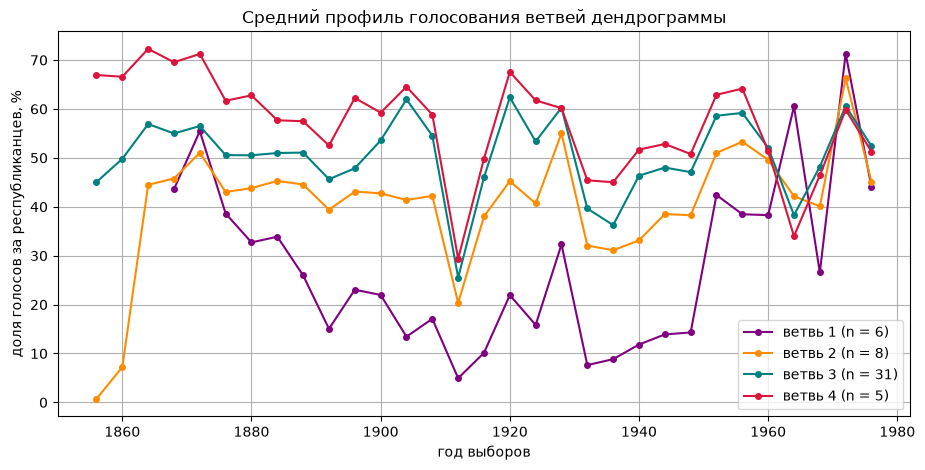

In [14]:
# Средняя доля голосов за республиканцев по годам для каждой ветви (по исходным данным, без медиан)
years = [int(c[1:]) for c in votes.columns]
plt.figure(figsize=(11, 5))
for b, color in zip(br_tab['ветвь'], ['purple', 'darkorange', 'teal', 'crimson']):
    plt.plot(years, votes[branch == b].mean(), marker='o', markersize=4, color=color,
             label=f'ветвь {b} (n = {(branch == b).sum()})')
plt.xlabel('год выборов')
plt.ylabel('доля голосов за республиканцев, %')
plt.title('Средний профиль голосования ветвей дендрограммы')
plt.legend()
plt.grid(True)
plt.show()

### Выводы по заданию 4
Дендрограмма прежде всего отделяет южные штаты, которые на протяжении большей части периода почти не голосовали за республиканцев, от остальной страны; это деление подтверждается и самым высоким silhouette (0.532 при k = 2). Внутри остальной части выделяются пограничные южные штаты с промежуточным профилем и небольшая группа традиционно республиканских штатов.

Профили ветвей по годам показывают, что региональные различия были особенно велики в конце XIX - первой половине XX века, а к 1950–1970-м годам кривые сближаются. Деление на четыре ветви удобно для интерпретации, но статистически надёжно в первую очередь деление на Юг и остальные штаты.